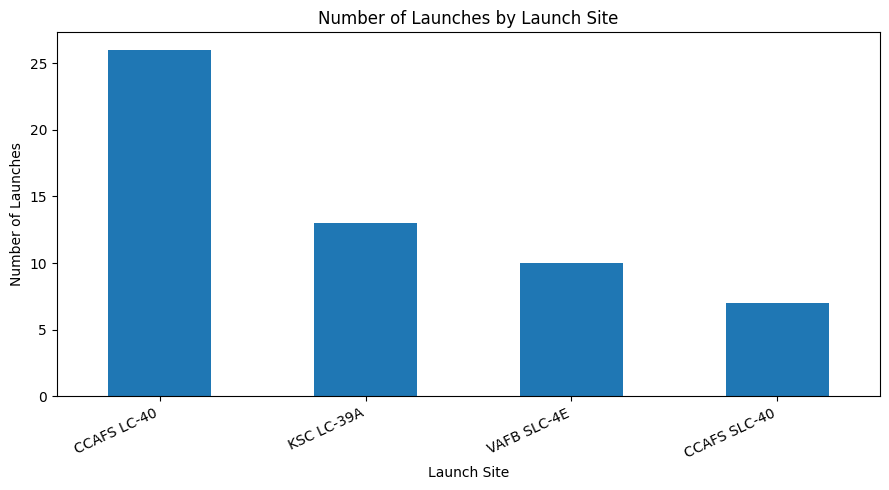

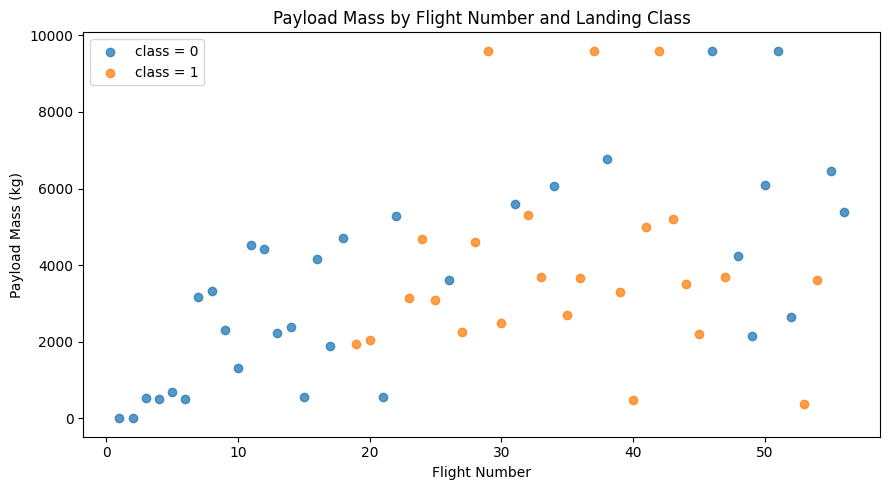

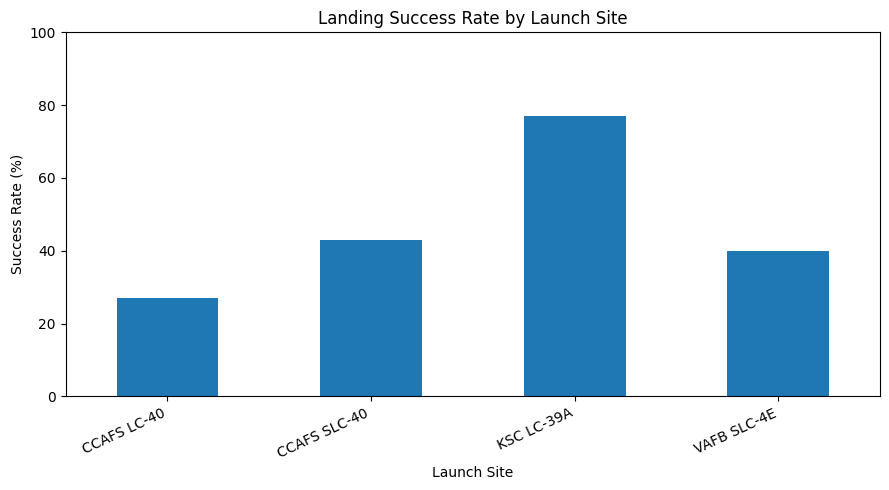

Launches by site:


,Launch Count
Launch Site,
CCAFS LC-40,26
KSC LC-39A,13
VAFB SLC-4E,10
CCAFS SLC-40,7


Landing success rate by site:


,Success Rate (%)
Launch Site,
CCAFS LC-40,26.92
CCAFS SLC-40,42.86
KSC LC-39A,76.92
VAFB SLC-4E,40.00


In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("/content/spacex_data")

df = pd.read_csv(data_dir / "spacex_launch_dash.csv")

# Remove the unnecessary index column if present
df = df.loc[:, ~df.columns.str.startswith("Unnamed:")]

# Ensure numeric data types
df["Flight Number"] = pd.to_numeric(
    df["Flight Number"], errors="coerce"
)
df["Payload Mass (kg)"] = pd.to_numeric(
    df["Payload Mass (kg)"], errors="coerce"
)
df["class"] = pd.to_numeric(df["class"], errors="coerce")

# 1. Launch count by launch site
plt.figure(figsize=(9, 5))
df["Launch Site"].value_counts().plot(kind="bar")
plt.title("Number of Launches by Launch Site")
plt.xlabel("Launch Site")
plt.ylabel("Number of Launches")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# 2. Payload mass vs. landing success class
plt.figure(figsize=(9, 5))
for label, group in df.groupby("class"):
    plt.scatter(
        group["Flight Number"],
        group["Payload Mass (kg)"],
        label=f"class = {label}",
        alpha=0.75
    )
plt.title("Payload Mass by Flight Number and Landing Class")
plt.xlabel("Flight Number")
plt.ylabel("Payload Mass (kg)")
plt.legend()
plt.tight_layout()
plt.show()

# 3. Success rate by launch site
success_rate = df.groupby("Launch Site")["class"].mean() * 100

plt.figure(figsize=(9, 5))
success_rate.plot(kind="bar")
plt.title("Landing Success Rate by Launch Site")
plt.xlabel("Launch Site")
plt.ylabel("Success Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print("Launches by site:")
display(df["Launch Site"].value_counts().rename("Launch Count").to_frame())

print("Landing success rate by site:")
display(success_rate.round(2).rename("Success Rate (%)").to_frame())


In [4]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("/content/spacex_data")

df = pd.read_csv(data_dir / "dataset_part_1.csv")
print("Columns:", df.columns.tolist())
display(df.head())

# Check whether the expected fields exist
required = ["Launch Site", "Payload Mass (kg)", "Orbit", "class"]
missing = [col for col in required if col not in df.columns]

if missing:
    print("Missing expected columns:", missing)
    print("Share the column names shown above so we can adapt the code.")
else:
    df["Payload Mass (kg)"] = pd.to_numeric(
        df["Payload Mass (kg)"], errors="coerce"
    )
    df["class"] = pd.to_numeric(df["class"], errors="coerce")

    # 1. Payload versus launch site
    plt.figure(figsize=(10, 5))
    df.boxplot(column="Payload Mass (kg)", by="Launch Site", rot=25)
    plt.title("Payload Mass Distribution by Launch Site")
    plt.suptitle("")
    plt.xlabel("Launch Site")
    plt.ylabel("Payload Mass (kg)")
    plt.tight_layout()
    plt.show()

    # 2. Landing success rate by orbit
    orbit_rate = df.groupby("Orbit")["class"].mean() * 100
    plt.figure(figsize=(10, 5))
    orbit_rate.sort_values().plot(kind="bar")
    plt.title("Landing Success Rate by Orbit")
    plt.xlabel("Orbit")
    plt.ylabel("Success Rate (%)")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    # 3. Yearly landing success trend
    date_col = next(
        (c for c in ["Date", "date", "Launch Date"] if c in df.columns),
        None
    )

    if date_col:
        df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
        df["Year"] = df[date_col].dt.year
        yearly = df.groupby("Year")["class"].mean() * 100

        plt.figure(figsize=(9, 5))
        yearly.plot(marker="o")
        plt.title("Yearly Landing Success Rate")
        plt.xlabel("Year")
        plt.ylabel("Success Rate (%)")
        plt.tight_layout()
        plt.show()
        display(yearly.rename("Success Rate (%)").to_frame().round(2))
    else:
        print("No date column found. We will identify the correct date field.")


Columns: ['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,NaN,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.0,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.0,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.0,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.0,GTO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857


Missing expected columns: ['Launch Site', 'Payload Mass (kg)', 'class']
Share the column names shown above so we can adapt the code.


<Figure size 1000x500 with 0 Axes>

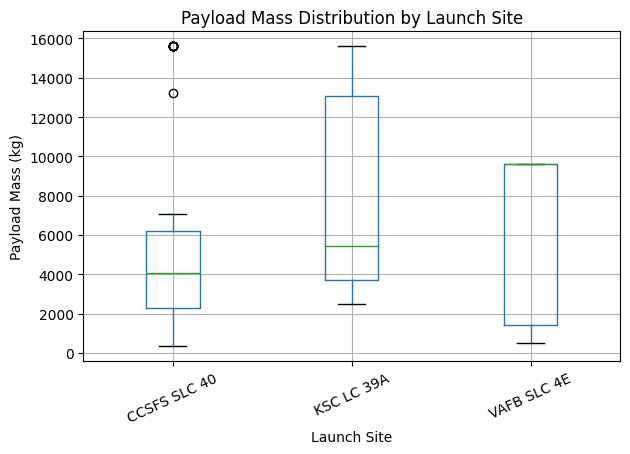

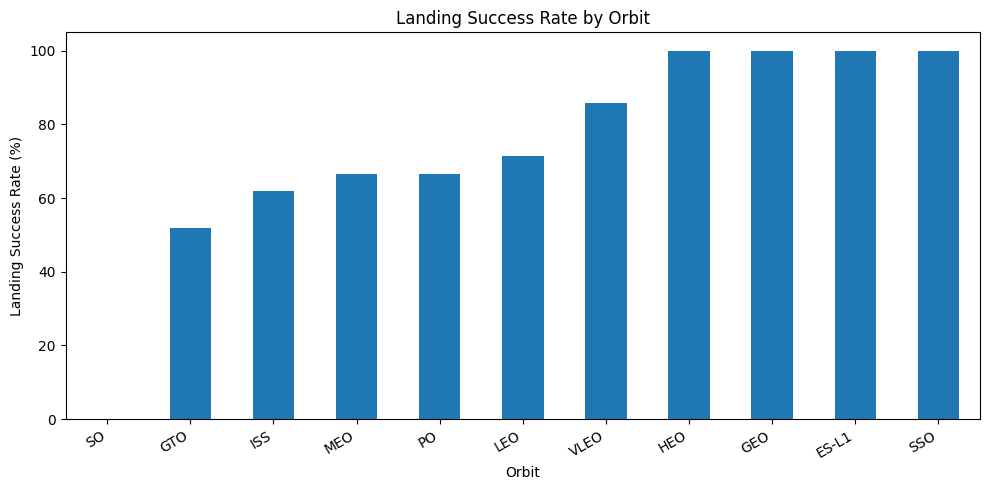

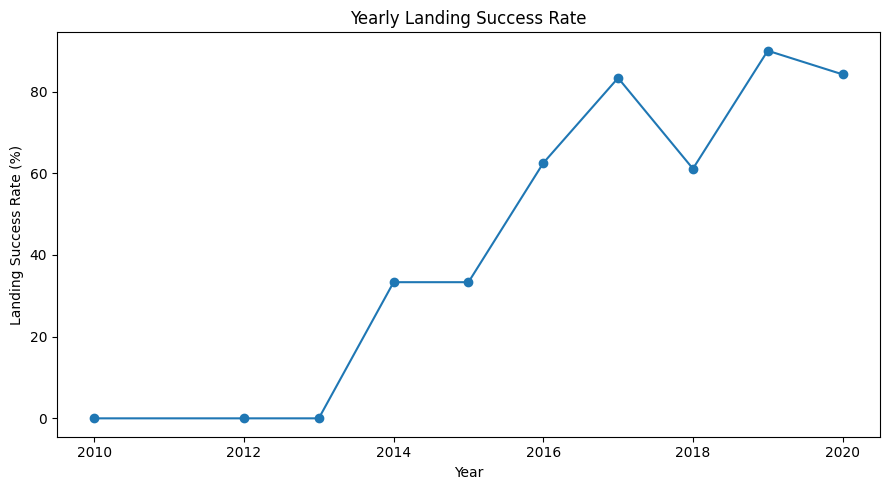

Landing success rate by orbit:


,Success Rate (%)
Orbit,
ES-L1,100.00
GEO,100.00
GTO,51.85
HEO,100.00
ISS,61.90
LEO,71.43
MEO,66.67
PO,66.67
SO,0.00


Yearly landing success rate:


,Success Rate (%)
Year,
2010,0.00
2012,0.00
2013,0.00
2014,33.33
2015,33.33
2016,62.50
2017,83.33
2018,61.11
2019,90.00


Saved dataset_part_1_processed.csv


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "dataset_part_1.csv")

# Convert columns to appropriate types
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["PayloadMass"] = pd.to_numeric(df["PayloadMass"], errors="coerce")
df["FlightNumber"] = pd.to_numeric(
    df["FlightNumber"], errors="coerce"
)

# Derive a landing success label from the Outcome column.
# This follows the common IBM lab definition:
# True Ocean, False Ocean, True RTLS, False RTLS, True ASDS, False ASDS.
successful_outcomes = [
    "True Ocean",
    "True RTLS",
    "True ASDS"
]
df["LandingSuccess"] = df["Outcome"].isin(successful_outcomes).astype(int)

# 1. Payload mass distribution by launch site
plt.figure(figsize=(10, 5))
df.boxplot(column="PayloadMass", by="LaunchSite", rot=25)
plt.title("Payload Mass Distribution by Launch Site")
plt.suptitle("")
plt.xlabel("Launch Site")
plt.ylabel("Payload Mass (kg)")
plt.tight_layout()
plt.show()

# 2. Landing success rate by orbit
orbit_rate = df.groupby("Orbit")["LandingSuccess"].mean() * 100

plt.figure(figsize=(10, 5))
orbit_rate.sort_values().plot(kind="bar")
plt.title("Landing Success Rate by Orbit")
plt.xlabel("Orbit")
plt.ylabel("Landing Success Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 3. Yearly landing success trend
df["Year"] = df["Date"].dt.year
yearly_rate = df.groupby("Year")["LandingSuccess"].mean() * 100

plt.figure(figsize=(9, 5))
yearly_rate.plot(marker="o")
plt.title("Yearly Landing Success Rate")
plt.xlabel("Year")
plt.ylabel("Landing Success Rate (%)")
plt.tight_layout()
plt.show()

print("Landing success rate by orbit:")
display(orbit_rate.round(2).rename("Success Rate (%)").to_frame())

print("Yearly landing success rate:")
display(yearly_rate.round(2).rename("Success Rate (%)").to_frame())

# Save the processed dataset
df.to_csv(data_dir / "dataset_part_1_processed.csv", index=False)
print("Saved dataset_part_1_processed.csv")


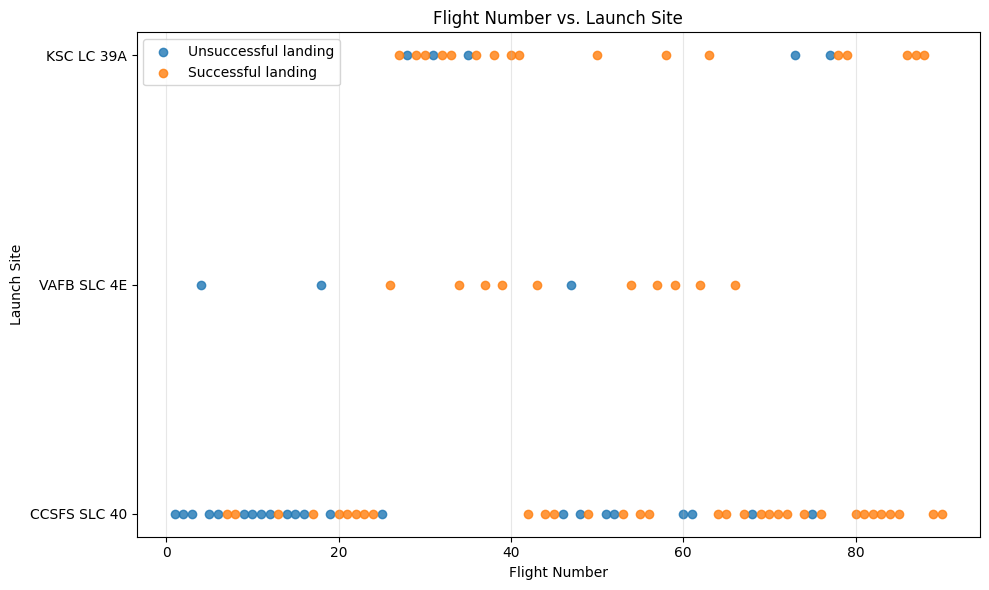

Chart saved successfully.


In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "dataset_part_1.csv")

# Convert outcome to a landing-success label
successful_outcomes = [
    "True Ocean",
    "True RTLS",
    "True ASDS"
]
df["LandingSuccess"] = df["Outcome"].isin(
    successful_outcomes
).astype(int)

# Flight Number vs Launch Site
plt.figure(figsize=(10, 6))

for success, group in df.groupby("LandingSuccess"):
    plt.scatter(
        group["FlightNumber"],
        group["LaunchSite"],
        label="Successful landing" if success == 1
        else "Unsuccessful landing",
        alpha=0.8
    )

plt.title("Flight Number vs. Launch Site")
plt.xlabel("Flight Number")
plt.ylabel("Launch Site")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    data_dir / "flight_number_vs_launch_site.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Chart saved successfully.")


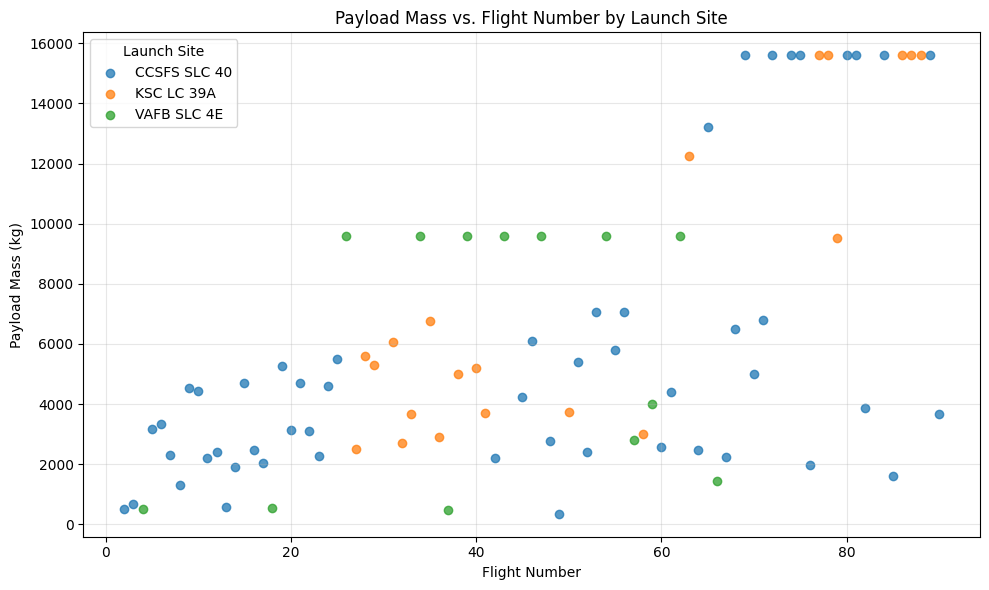

Payload chart saved successfully.


In [7]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "dataset_part_1.csv")

df["PayloadMass"] = pd.to_numeric(
    df["PayloadMass"], errors="coerce"
)

plt.figure(figsize=(10, 6))

for site, group in df.groupby("LaunchSite"):
    plt.scatter(
        group["FlightNumber"],
        group["PayloadMass"],
        label=site,
        alpha=0.75
    )

plt.title("Payload Mass vs. Flight Number by Launch Site")
plt.xlabel("Flight Number")
plt.ylabel("Payload Mass (kg)")
plt.legend(title="Launch Site")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    data_dir / "payload_vs_launch_site.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Payload chart saved successfully.")


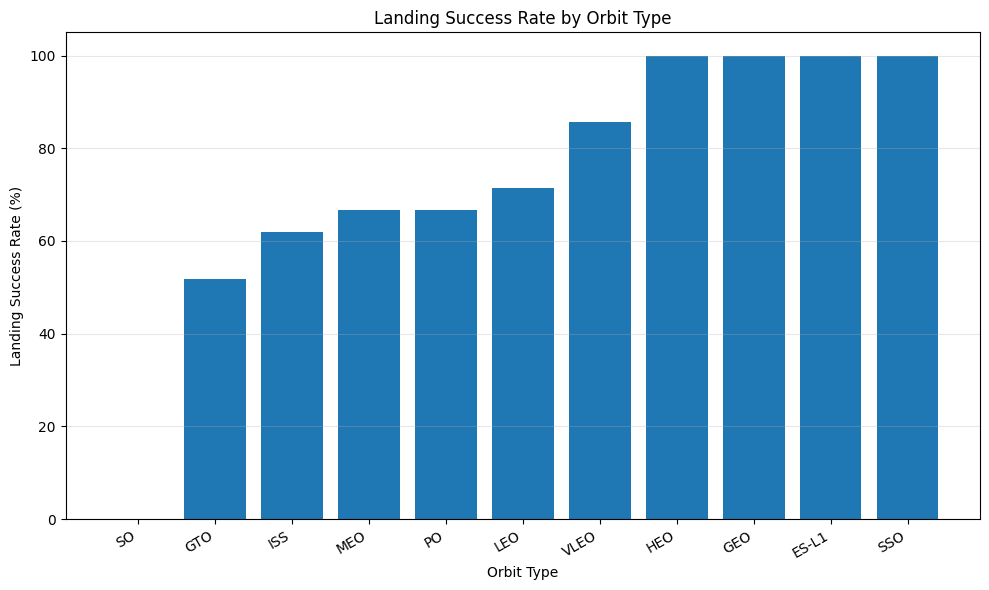

Success rate by orbit:


,Orbit,count,SuccessRatePercent
8,SO,1,0.00
2,GTO,27,51.85
4,ISS,21,61.90
6,MEO,3,66.67
7,PO,9,66.67
5,LEO,7,71.43
10,VLEO,14,85.71
3,HEO,1,100.00
1,GEO,1,100.00
0,ES-L1,1,100.00


Chart saved successfully.


In [8]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "dataset_part_1.csv")

# Define successful landing outcomes
successful_outcomes = [
    "True Ocean",
    "True RTLS",
    "True ASDS"
]

df["LandingSuccess"] = (
    df["Outcome"].isin(successful_outcomes).astype(int)
)

# Calculate success rate by orbit
orbit_results = (
    df.groupby("Orbit")["LandingSuccess"]
    .agg(["mean", "count"])
    .reset_index()
)

orbit_results["SuccessRatePercent"] = orbit_results["mean"] * 100
orbit_results = orbit_results.sort_values("SuccessRatePercent")

# Plot
plt.figure(figsize=(10, 6))
plt.bar(
    orbit_results["Orbit"],
    orbit_results["SuccessRatePercent"]
)

plt.title("Landing Success Rate by Orbit Type")
plt.xlabel("Orbit Type")
plt.ylabel("Landing Success Rate (%)")
plt.ylim(0, 105)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    data_dir / "success_rate_by_orbit.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Success rate by orbit:")
display(
    orbit_results[
        ["Orbit", "count", "SuccessRatePercent"]
    ].round(2)
)

print("Chart saved successfully.")


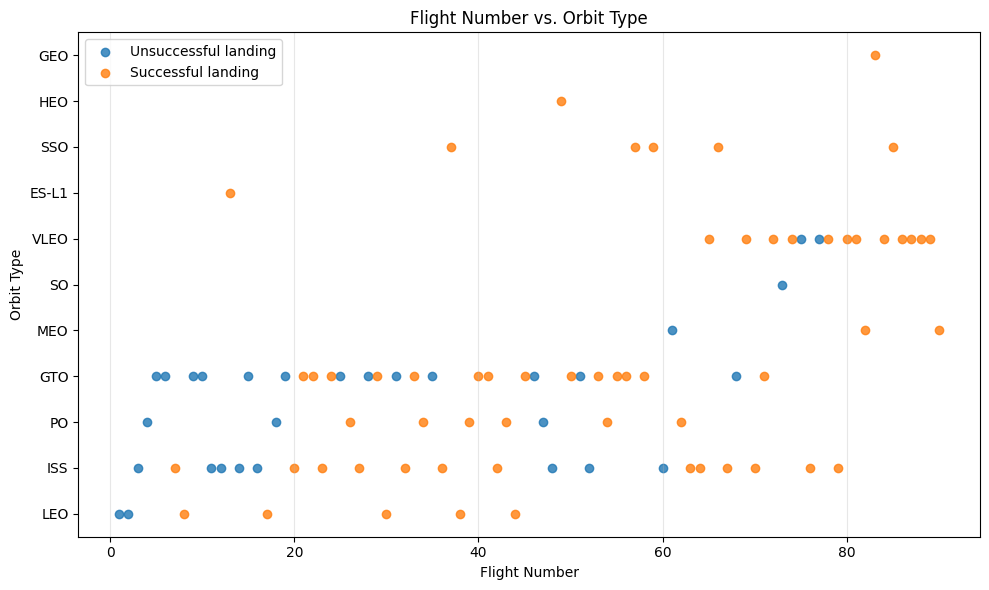

Flight Number vs. Orbit chart saved.


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "dataset_part_1.csv")

successful_outcomes = [
    "True Ocean", "True RTLS", "True ASDS"
]
df["LandingSuccess"] = df["Outcome"].isin(
    successful_outcomes
).astype(int)

plt.figure(figsize=(10, 6))

for success, group in df.groupby("LandingSuccess"):
    plt.scatter(
        group["FlightNumber"],
        group["Orbit"],
        label=(
            "Successful landing"
            if success == 1
            else "Unsuccessful landing"
        ),
        alpha=0.8
    )

plt.title("Flight Number vs. Orbit Type")
plt.xlabel("Flight Number")
plt.ylabel("Orbit Type")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    data_dir / "flight_number_vs_orbit.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Flight Number vs. Orbit chart saved.")


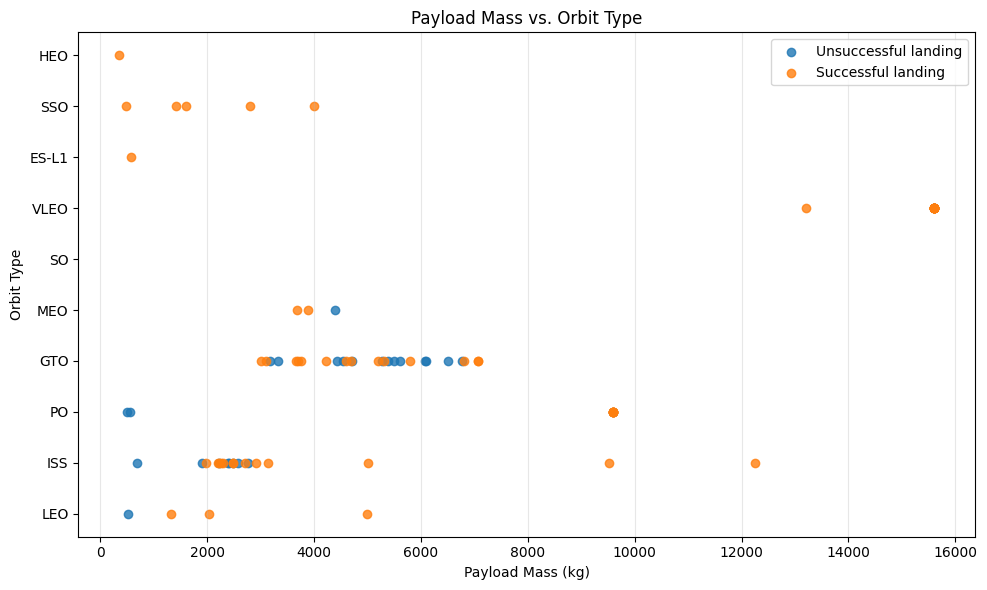

Payload vs. Orbit chart saved.


In [10]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "dataset_part_1.csv")

df["PayloadMass"] = pd.to_numeric(
    df["PayloadMass"], errors="coerce"
)

successful_outcomes = [
    "True Ocean", "True RTLS", "True ASDS"
]
df["LandingSuccess"] = df["Outcome"].isin(
    successful_outcomes
).astype(int)

plt.figure(figsize=(10, 6))

for success, group in df.groupby("LandingSuccess"):
    plt.scatter(
        group["PayloadMass"],
        group["Orbit"],
        label=(
            "Successful landing"
            if success == 1
            else "Unsuccessful landing"
        ),
        alpha=0.8
    )

plt.title("Payload Mass vs. Orbit Type")
plt.xlabel("Payload Mass (kg)")
plt.ylabel("Orbit Type")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    data_dir / "payload_vs_orbit.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Payload vs. Orbit chart saved.")


In [11]:

import pandas as pd
from pathlib import Path

data_dir = Path("/content/spacex_data")

for filename in [
    "dataset_part_2.csv",
    "dataset_part_3.csv"
]:
    df_sql = pd.read_csv(data_dir / filename)

    print("\nDataset:", filename)
    print("Shape:", df_sql.shape)
    print("Columns:", df_sql.columns.tolist())
    display(df_sql.head(3))



Dataset: dataset_part_2.csv
Shape: (90, 18)
Columns: ['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0



Dataset: dataset_part_3.csv
Shape: (90, 4)
Columns: ['Orbit', 'LaunchSite', 'LandingPad', 'Serial']


,Orbit,LaunchSite,LandingPad,Serial
0,0,1,0,1
1,0,1,0,0
2,0,1,0,0


In [12]:

import pandas as pd
import sqlite3
from pathlib import Path

data_dir = Path("/content/spacex_data")

df = pd.read_csv(data_dir / "dataset_part_2.csv")

# Prepare a SQL-compatible table
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["PayloadMass"] = pd.to_numeric(
    df["PayloadMass"], errors="coerce"
)

conn = sqlite3.connect(":memory:")
df.to_sql("spacex", conn, index=False, if_exists="replace")

queries = {
    "1. Unique launch sites": """
        SELECT DISTINCT LaunchSite
        FROM spacex
        ORDER BY LaunchSite;
    """,

    "2. Total launches per site": """
        SELECT LaunchSite, COUNT(*) AS LaunchCount
        FROM spacex
        GROUP BY LaunchSite
        ORDER BY LaunchCount DESC;
    """,

    "3. Average payload by orbit": """
        SELECT Orbit,
               ROUND(AVG(PayloadMass), 2) AS AvgPayloadKg,
               COUNT(*) AS Records
        FROM spacex
        GROUP BY Orbit
        ORDER BY AvgPayloadKg DESC;
    """,

    "4. Successful and unsuccessful landing counts": """
        SELECT Class, COUNT(*) AS RecordCount
        FROM spacex
        GROUP BY Class
        ORDER BY Class;
    """,

    "5. Booster versions by number of records": """
        SELECT BoosterVersion, COUNT(*) AS RecordCount
        FROM spacex
        GROUP BY BoosterVersion
        ORDER BY RecordCount DESC;
    """,

    "6. Launches by year": """
        SELECT strftime('%Y', Date) AS LaunchYear,
               COUNT(*) AS LaunchCount
        FROM spacex
        WHERE Date IS NOT NULL
        GROUP BY LaunchYear
        ORDER BY LaunchYear;
    """
}

for title, query in queries.items():
    print("\n" + "=" * 60)
    print(title)
    result = pd.read_sql_query(query, conn)
    display(result)

conn.close()



1. Unique launch sites


,LaunchSite
0,CCAFS SLC 40
1,KSC LC 39A
2,VAFB SLC 4E



2. Total launches per site


,LaunchSite,LaunchCount
0,CCAFS SLC 40,55
1,KSC LC 39A,22
2,VAFB SLC 4E,13



3. Average payload by orbit


...

,Class,RecordCount
0,0,30
1,1,60



5. Booster versions by number of records


,BoosterVersion,RecordCount
0,Falcon 9,90



6. Launches by year


,LaunchYear,LaunchCount
0,2010,1
1,2012,1
2,2013,3
3,2014,6
4,2015,6
5,2016,8
6,2017,18
7,2018,18
8,2019,10
9,2020,19


In [13]:

import pandas as pd
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "dataset_part_2.csv")

print("Outcome categories:")
display(df["Outcome"].value_counts(dropna=False).to_frame("Count"))

print("\nLanding pad categories:")
display(df["LandingPad"].value_counts(dropna=False).to_frame("Count"))

print("\nCustomer categories:")
if "Customer" in df.columns:
    display(df["Customer"].value_counts(dropna=False).head(15).to_frame("Count"))
else:
    print("Customer column is not available.")

print("\nBooster version categories:")
display(df["BoosterVersion"].value_counts(dropna=False).to_frame("Count"))

print("\nEarliest and latest launch dates:")
print(df["Date"].min(), "to", df["Date"].max())


Outcome categories:


,Count
Outcome,
True ASDS,41
None None,19
True RTLS,14
False ASDS,6
True Ocean,5
False Ocean,2
None ASDS,2
False RTLS,1



Landing pad categories:


,Count
LandingPad,
5e9e3032383ecb6bb234e7ca,35
NaN,26
5e9e3032383ecb267a34e7c7,13
5e9e3033383ecbb9e534e7cc,12
5e9e3032383ecb761634e7cb,2
5e9e3032383ecb554034e7c9,2



Customer categories:
Customer column is not available.

Booster version categories:


,Count
BoosterVersion,
Falcon 9,90



Earliest and latest launch dates:
2010-06-04 to 2020-11-05


In [14]:

import pandas as pd
import sqlite3
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "dataset_part_2.csv")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["PayloadMass"] = pd.to_numeric(df["PayloadMass"], errors="coerce")

conn = sqlite3.connect(":memory:")
df.to_sql("spacex", conn, index=False, if_exists="replace")

queries = {
    "1. Total successful and unsuccessful landing classes": """
        SELECT Class, COUNT(*) AS RecordCount
        FROM spacex
        GROUP BY Class
        ORDER BY Class;
    """,

    "2. First successful ground landing": """
        SELECT Date, FlightNumber, Outcome, LandingPad
        FROM spacex
        WHERE Outcome = 'True RTLS'
          AND Date IS NOT NULL
        ORDER BY Date
        LIMIT 1;
    """,

    "3. Successful drone-ship landings, payload 4000-6000 kg": """
        SELECT FlightNumber, Date, PayloadMass, Outcome, LandingPad
        FROM spacex
        WHERE Outcome = 'True ASDS'
          AND PayloadMass > 4000
          AND PayloadMass < 6000
        ORDER BY Date;
    """,

    "4. Boosters with maximum payload mass": """
        SELECT Serial, BoosterVersion, PayloadMass, FlightNumber, Date
        FROM spacex
        WHERE PayloadMass = (
            SELECT MAX(PayloadMass) FROM spacex
        );
    """,

    "5. Failed drone-ship outcomes during 2015": """
        SELECT Date, FlightNumber, Outcome, BoosterVersion,
               LaunchSite, PayloadMass
        FROM spacex
        WHERE Date >= '2015-01-01'
          AND Date < '2016-01-01'
          AND Outcome = 'False ASDS'
        ORDER BY Date;
    """,

    "6. Landing outcomes ranked from 2010-06-04 to 2017-03-20": """
        SELECT Outcome, COUNT(*) AS OutcomeCount
        FROM spacex
        WHERE Date >= '2010-06-04'
          AND Date <= '2017-03-20'
        GROUP BY Outcome
        ORDER BY OutcomeCount DESC;
    """
}

for title, query in queries.items():
    print("\n" + "=" * 70)
    print(title)
    result = pd.read_sql_query(query, conn)
    display(result)

conn.close()



1. Total successful and unsuccessful landing classes


,Class,RecordCount
0,0,30
1,1,60



2. First successful ground landing


,Date,FlightNumber,Outcome,LandingPad
0,2015-12-22 00:00:00,17,True RTLS,5e9e3032383ecb267a34e7c7



3. Successful drone-ship landings, payload 4000-6000 kg


...

,Serial,BoosterVersion,PayloadMass,FlightNumber,Date
0,B1048,Falcon 9,15600.0,69,2019-11-11 00:00:00
1,B1051,Falcon 9,15600.0,74,2020-01-29 00:00:00
2,B1048,Falcon 9,15600.0,77,2020-03-18 00:00:00



5. Failed drone-ship outcomes during 2015


,Date,FlightNumber,Outcome,BoosterVersion,LaunchSite,PayloadMass
0,2015-01-10 00:00:00,12,False ASDS,Falcon 9,CCAFS SLC 40,2395.0
1,2015-04-14 00:00:00,14,False ASDS,Falcon 9,CCAFS SLC 40,1898.0



6. Landing outcomes ranked from 2010-06-04 to 2017-03-20


,Outcome,OutcomeCount
0,None None,9
1,True ASDS,5
2,False ASDS,4
3,True RTLS,3
4,True Ocean,3
5,None ASDS,2
6,False Ocean,2


Model comparison:


,Model,Test Accuracy (%)
1,Decision Tree,82.61
2,K-Nearest Neighbors,82.61
0,Logistic Regression,78.26
3,Support Vector Machine,78.26


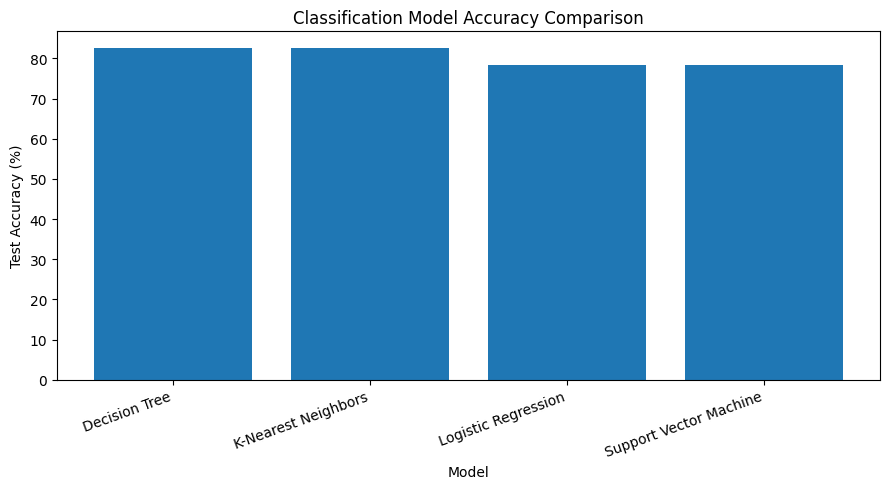

Best model by test accuracy: Decision Tree

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         8
           1       0.79      1.00      0.88        15

    accuracy                           0.83        23
   macro avg       0.89      0.75      0.77        23
weighted avg       0.86      0.83      0.81        23



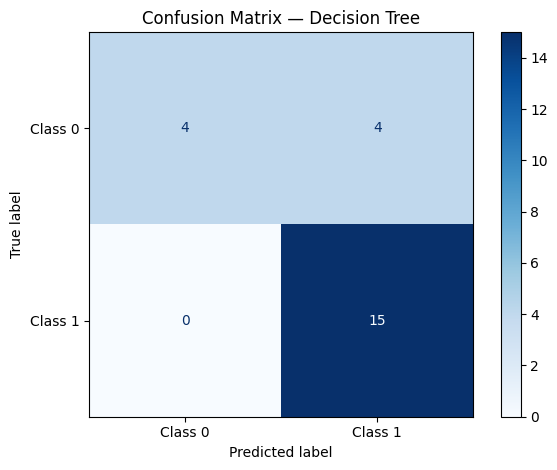

Saved model comparison and confusion matrix.


In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "dataset_part_2.csv")

# Target: landing success class
y = df["Class"].astype(int)

# Use features available before the landing outcome.
# Exclude Outcome, LandingPad, and Class to avoid target leakage.
features = [
    "FlightNumber",
    "PayloadMass",
    "Orbit",
    "LaunchSite",
    "Flights",
    "GridFins",
    "Reused",
    "Legs",
    "Block",
    "ReusedCount"
]

X = df[features].copy()

numeric_features = [
    "FlightNumber", "PayloadMass", "Flights",
    "Block", "ReusedCount"
]
categorical_features = [
    "Orbit", "LaunchSite", "GridFins", "Reused", "Legs"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, random_state=42
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel="rbf", random_state=42)
}

results = []
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    results.append({
        "Model": name,
        "Test Accuracy (%)": round(accuracy * 100, 2)
    })
    fitted_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    "Test Accuracy (%)", ascending=False
)

print("Model comparison:")
display(results_df)

# Save the comparison table
results_df.to_csv(
    data_dir / "model_accuracy_results.csv", index=False
)

# Plot model accuracies
plt.figure(figsize=(9, 5))
plt.bar(
    results_df["Model"],
    results_df["Test Accuracy (%)"]
)
plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(
    data_dir / "model_accuracy_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Evaluate the best model on the held-out test set
best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_predictions = best_model.predict(X_test)

print("Best model by test accuracy:", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_predictions, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["Class 0", "Class 1"],
    cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.savefig(
    data_dir / "best_model_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Saved model comparison and confusion matrix.")


In [16]:

!pip -q install folium


In [17]:

import pandas as pd
import folium
from pathlib import Path
from IPython.display import display

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "spacex_launch_geo.csv")

# Check required geographic columns
required = ["Lat", "Long", "Launch Site", "Flight Number",
            "Mission Outcome", "class"]

missing = [col for col in required if col not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Remove records without coordinates
df = df.dropna(subset=["Lat", "Long"]).copy()

# Create a map centered on the launch sites
launch_map = folium.Map(
    location=[df["Lat"].mean(), df["Long"].mean()],
    zoom_start=5,
    tiles="OpenStreetMap"
)

# Add one marker for each unique launch site
for site, group in df.groupby("Launch Site"):
    lat = group["Lat"].mean()
    lon = group["Long"].mean()

    popup_text = (
        f"<b>Launch Site:</b> {site}<br>"
        f"<b>Launch records:</b> {len(group)}<br>"
        f"<b>Latitude:</b> {lat:.5f}<br>"
        f"<b>Longitude:</b> {lon:.5f}"
    )

    folium.Marker(
        location=[lat, lon],
        tooltip=site,
        popup=folium.Popup(popup_text, max_width=300),
        icon=folium.Icon(color="blue", icon="rocket", prefix="fa")
    ).add_to(launch_map)

# Add individual launch records as circle markers
for _, row in df.iterrows():
    folium.CircleMarker(
        location=[row["Lat"], row["Long"]],
        radius=4,
        color="green" if row["class"] == 1 else "red",
        fill=True,
        fill_opacity=0.65,
        tooltip=(
            f"Flight {row['Flight Number']} | "
            f"{row['Launch Site']} | "
            f"Outcome: {row['Mission Outcome']}"
        )
    ).add_to(launch_map)

# Save the interactive map
map_path = data_dir / "spacex_launch_map.html"
launch_map.save(str(map_path))

display(launch_map)
print("Interactive map saved to:", map_path)
print("Records mapped:", len(df))
print("Unique launch sites:", df["Launch Site"].nunique())


Interactive map saved to: /content/spacex_data/spacex_launch_map.html
Records mapped: 56
Unique launch sites: 4


In [18]:

import numpy as np
import pandas as pd
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "spacex_launch_geo.csv")

sites = (
    df.groupby("Launch Site")[["Lat", "Long"]]
    .mean()
    .dropna()
    .reset_index()
)

def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius_km * np.arcsin(np.sqrt(a))

distances = []

for i in range(len(sites)):
    for j in range(i + 1, len(sites)):
        distance = haversine_km(
            sites.loc[i, "Lat"],
            sites.loc[i, "Long"],
            sites.loc[j, "Lat"],
            sites.loc[j, "Long"]
        )

        distances.append({
            "Launch Site 1": sites.loc[i, "Launch Site"],
            "Launch Site 2": sites.loc[j, "Launch Site"],
            "Approx Distance (km)": round(distance, 2)
        })

distance_df = pd.DataFrame(distances)
display(distance_df)

distance_df.to_csv(
    data_dir / "launch_site_distances.csv",
    index=False
)
print("Proximity analysis saved.")


,Launch Site 1,Launch Site 2,Approx Distance (km)
0,CCAFS LC-40,CCAFS SLC-40,0.11
1,CCAFS LC-40,KSC LC-39A,6.90
2,CCAFS LC-40,VAFB SLC-4E,3825.84
3,CCAFS SLC-40,KSC LC-39A,6.93
4,CCAFS SLC-40,VAFB SLC-4E,3825.85
5,KSC LC-39A,VAFB SLC-4E,3819.05


Proximity analysis saved.


In [19]:

!pip -q install plotly dash


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 32.6 MB/s eta 0:00:00


In [20]:

import pandas as pd
import plotly.express as px
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "spacex_launch_dash.csv")

df = df.loc[:, ~df.columns.str.startswith("Unnamed:")]
df["Payload Mass (kg)"] = pd.to_numeric(
    df["Payload Mass (kg)"], errors="coerce"
)

# Verify the meaning of class labels against Mission Outcome.
print("Mission outcome by class:")
display(pd.crosstab(df["class"], df["Mission Outcome"]))

# Pie chart of the dataset's landing class
class_counts = (
    df["class"]
    .map({0: "Class 0", 1: "Class 1"})
    .value_counts()
    .rename_axis("Landing Class")
    .reset_index(name="Count")
)

fig_pie = px.pie(
    class_counts,
    names="Landing Class",
    values="Count",
    title="Distribution of Landing Classes"
)
fig_pie.write_html(str(data_dir / "landing_success_pie.html"))
fig_pie.show()

# Payload vs landing class
df["Landing Class"] = df["class"].map({
    0: "Class 0",
    1: "Class 1"
})

fig_scatter = px.scatter(
    df,
    x="Payload Mass (kg)",
    y="Landing Class",
    color="Landing Class",
    hover_data=[
        "Flight Number",
        "Launch Site",
        "Mission Outcome"
    ],
    title="Payload Mass vs Landing Class"
)
fig_scatter.write_html(
    str(data_dir / "payload_vs_landing_class.html")
)
fig_scatter.show()

print("Saved both interactive Plotly charts.")


Mission outcome by class:


Mission Outcome,Failure (in flight),Success,Success (payload status unclear)
class,,,
0,0,32,0
1,1,22,1


Saved both interactive Plotly charts.


In [21]:

import pandas as pd
import plotly.express as px
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "spacex_launch_dash.csv")

df = df.loc[:, ~df.columns.str.startswith("Unnamed:")]
df["Payload Mass (kg)"] = pd.to_numeric(
    df["Payload Mass (kg)"], errors="coerce"
)
df["class"] = pd.to_numeric(df["class"], errors="coerce")

df = df.dropna(subset=["Payload Mass (kg)", "class"])

# 1. Pie chart: class distribution
class_counts = (
    df["class"]
    .value_counts()
    .sort_index()
    .rename_axis("Class")
    .reset_index(name="Count")
)
class_counts["Class"] = class_counts["Class"].astype(str)

fig_pie = px.pie(
    class_counts,
    names="Class",
    values="Count",
    title="Distribution of Class Labels",
    hole=0.35
)
fig_pie.write_html(str(data_dir / "landing_class_pie.html"))
fig_pie.show()

# 2. Scatter plot: payload vs numeric class
fig_scatter = px.scatter(
    df,
    x="Payload Mass (kg)",
    y="class",
    color="class",
    hover_data=[
        "Flight Number",
        "Launch Site",
        "Mission Outcome"
    ],
    title="Payload Mass vs Class Label"
)

fig_scatter.update_yaxes(
    tickmode="array",
    tickvals=[0, 1],
    ticktext=["Class 0", "Class 1"]
)

fig_scatter.update_traces(marker={"size": 10, "opacity": 0.8})

fig_scatter.write_html(
    str(data_dir / "payload_vs_class.html")
)
fig_scatter.show()

print("Rows plotted:", len(df))
print("Saved updated interactive charts.")


Rows plotted: 56
Saved updated interactive charts.


In [22]:

!pip -q install dash jupyter-dash


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 38.9 MB/s eta 0:00:00


In [23]:

import pandas as pd
import plotly.express as px
from dash import Dash, dcc, html, Input, Output
from pathlib import Path

data_dir = Path("/content/spacex_data")
df = pd.read_csv(data_dir / "spacex_launch_dash.csv")
df = df.loc[:, ~df.columns.str.startswith("Unnamed:")]

df["Payload Mass (kg)"] = pd.to_numeric(
    df["Payload Mass (kg)"], errors="coerce"
)
df["class"] = pd.to_numeric(df["class"], errors="coerce")

app = Dash(__name__)

sites = sorted(df["Launch Site"].dropna().unique())

app.layout = html.Div([
    html.H1("SpaceX Launch Analytics Dashboard"),

    html.Label("Select Launch Site:"),
    dcc.Dropdown(
        id="site-dropdown",
        options=[{"label": "All Sites", "value": "ALL"}] +
                [{"label": s, "value": s} for s in sites],
        value="ALL",
        clearable=False
    ),

    dcc.Graph(id="class-pie"),
    dcc.Graph(id="payload-scatter")
])

@app.callback(
    Output("class-pie", "figure"),
    Output("payload-scatter", "figure"),
    Input("site-dropdown", "value")
)
def update_dashboard(selected_site):
    filtered = df.copy()

    if selected_site != "ALL":
        filtered = filtered[
            filtered["Launch Site"] == selected_site
        ]

    counts = (
        filtered["class"]
        .value_counts()
        .sort_index()
        .rename_axis("Class")
        .reset_index(name="Count")
    )
    counts["Class"] = counts["Class"].astype(str)

    pie = px.pie(
        counts,
        names="Class",
        values="Count",
        title="Distribution of Class Labels"
    )

    scatter = px.scatter(
        filtered.dropna(subset=["Payload Mass (kg)", "class"]),
        x="Payload Mass (kg)",
        y="class",
        color="class",
        hover_data=[
            "Flight Number",
            "Launch Site",
            "Mission Outcome"
        ],
        title="Payload Mass vs Class Label"
    )
    scatter.update_yaxes(
        tickmode="array",
        tickvals=[0, 1],
        ticktext=["Class 0", "Class 1"]
    )

    return pie, scatter

# Export a static HTML summary as a fallback deliverable
pie_counts = df["class"].value_counts().sort_index()
summary = px.pie(
    values=pie_counts.values,
    names=[f"Class {i}" for i in pie_counts.index],
    title="Distribution of Class Labels"
)
summary.write_html(str(data_dir / "dashboard_pie_summary.html"))

scatter_summary = px.scatter(
    df.dropna(subset=["Payload Mass (kg)", "class"]),
    x="Payload Mass (kg)",
    y="class",
    color="class",
    hover_data=["Flight Number", "Launch Site", "Mission Outcome"],
    title="Payload Mass vs Class Label"
)
scatter_summary.write_html(
    str(data_dir / "dashboard_payload_scatter.html")
)

print("Dash application defined successfully.")
print("Launch sites:", sites)
print("Static dashboard charts saved.")


Dash application defined successfully.
Launch sites: ['CCAFS LC-40', 'CCAFS SLC-40', 'KSC LC-39A', 'VAFB SLC-4E']
Static dashboard charts saved.


In [24]:

from pathlib import Path
import zipfile
from google.colab import files

data_dir = Path("/content/spacex_data")
zip_path = Path("/content/SpaceX_Capstone_Results.zip")

# Include generated results and datasets, excluding temporary files
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in data_dir.rglob("*"):
        if path.is_file() and not path.name.startswith("."):
            archive.write(path, arcname=path.relative_to(data_dir.parent))

print("ZIP created:", zip_path)
print("File size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

files.download(str(zip_path))


ZIP created: /content/SpaceX_Capstone_Results.zip
File size (MB): 8.11


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>